# Churn — entraînement et évaluation des modèles

Ce notebook entraîne **deux modèles** et les compare.

| Modèle | Colonnes | Ce qu'il apprend |
|---|---|---|
| **Opérationnel** | 11 (avec `STATUT`) | « un client suspendu part » |
| **Comportemental** | 10 (sans `STATUT`) | « ce client actif se désengage » |

**Entrée** : `data/final/modele_operationnel.csv` et `modele_comportement.csv`

## ⚠️ Une limite à connaître avant de commencer

La table contient **une seule ligne par contrat**, avec des mesures agrégées sur janvier→novembre et **un seul label** (le statut de décembre).

J'ai vérifié : le `STATUT` ne change **jamais** pendant 2025 (33 849 contrats sur 33 849). Il n'existe donc **aucun label intermédiaire**.

**Conséquence** : la validation temporelle (« entraîner sur janv–juin, tester sur juil–nov ») est **impossible**. Tout ce qu'on peut faire ici, c'est une validation croisée sur des clients différents.

Les scores obtenus seront donc **optimistes** par rapport à la réalité d'un déploiement. Il faut le garder en tête.

## 0. Préparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     train_test_split, cross_val_predict)
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, confusion_matrix,
                             classification_report)
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FINAL = ROOT / 'data' / 'final'

# les deux versions prêtes pour le modèle
operationnel = pd.read_csv(FINAL / 'modele_operationnel.csv',
                           keep_default_na=False, na_values=[''], low_memory=False)
comportemental = pd.read_csv(FINAL / 'modele_comportement.csv',
                             keep_default_na=False, na_values=[''], low_memory=False)

print('opérationnel   :', operationnel.shape)
print('comportemental :', comportemental.shape)
print()
print('colonnes opérationnel   :', list(operationnel.columns))
print('colonnes comportemental :', list(comportemental.columns))

opérationnel   : (34000, 10)
comportemental : (34000, 9)

colonnes opérationnel   : ['ANC_M', 'VOLUME_SESSION', 'MNT_RECH', 'MNT_FORFAIT', 'APPEL_TOTAL', 'SMS_TOTAL', 'HANDSET', 'OFFRE', 'STATUT', 'churn']
colonnes comportemental : ['ANC_M', 'VOLUME_SESSION', 'MNT_RECH', 'MNT_FORFAIT', 'APPEL_TOTAL', 'SMS_TOTAL', 'HANDSET', 'OFFRE', 'churn']


In [2]:
# on a besoin du STATUT en clair pour l'analyse par population.
# all_tables_clean.csv contient STATUT encodé ; all_tables.csv contient le texte.
# les deux fichiers ont le même ordre de lignes (aucune ligne supprimée).
brut = pd.read_csv(FINAL / 'all_tables.csv', keep_default_na=False,
                   na_values=[''], low_memory=False)

print('même nombre de lignes :', len(brut) == len(operationnel))
print()
print('correspondance entre le STATUT texte et son code :')
print(pd.crosstab(brut['STATUT'], operationnel['STATUT']).to_string())
print()
print('→ A = 0, S = 1')

même nombre de lignes : True

correspondance entre le STATUT texte et son code :
STATUT      0     1
STATUT             
A       25466     0
S           0  8534

→ A = 0, S = 1


## 1. Préparation des données

`X` contient les variables, `y` contient le label. `churn` ne doit **jamais** être dans `X` (ce serait donner la réponse).

In [3]:
y = operationnel['churn']

X_op = operationnel.drop(columns=['churn'])
X_co = comportemental.drop(columns=['churn'])

print(f'y  : {y.shape[0]:,} labels  |  churn = {y.mean()*100:.2f} %')
print(f'X opérationnel   : {X_op.shape}')
print(f'X comportemental : {X_co.shape}')
print()
# la seule différence doit être STATUT
difference = set(X_op.columns) - set(X_co.columns)
print('colonne(s) en plus dans le modèle opérationnel :', difference)
assert difference == {'STATUT'}, 'différence inattendue entre les deux versions'

y  : 34,000 labels  |  churn = 28.12 %
X opérationnel   : (34000, 9)
X comportemental : (34000, 8)

colonne(s) en plus dans le modèle opérationnel : {'STATUT'}


In [4]:
# trace du découpage : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X_op, y, test_size=0.20, random_state=42, stratify=y)

print(f'entraînement : {len(X_train):,} clients  ({y_train.mean()*100:.2f} % de churn)')
print(f'test         : {len(X_test):,} clients  ({y_test.mean()*100:.2f} % de churn)')
print()
print('stratify=y garantit la même proportion de churn des deux côtés.')

entraînement : 27,200 clients  (28.12 % de churn)
test         : 6,800 clients  (28.12 % de churn)

stratify=y garantit la même proportion de churn des deux côtés.


## 2. Entraînement des modèles

Quatre modèles au total : deux algorithmes × deux jeux de colonnes.

| Algorithme | Pourquoi |
|---|---|
| **HistGradientBoosting** | arbres, gère le non-linéaire et les interactions |
| **LogisticRegression** | référence linéaire, interprétable |

Comparer les deux algorithmes évite d'attribuer au jeu de colonnes un gain qui vient en réalité du choix du modèle.

In [5]:
def creer_modeles():
    """Retourne un dictionnaire de modèles non entraînés."""
    return {
        'GradientBoosting': HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.06, random_state=42),
        'LogisticRegression': make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    }

modeles = {}
for algo_nom, algo in creer_modeles().items():
    for version_nom, X in [('opérationnel', X_op), ('comportemental', X_co)]:
        cle = f'{algo_nom} / {version_nom}'
        algo.fit(X, y)
        modeles[cle] = {'modele': algo, 'X': X, 'version': version_nom,
                        'algo': algo_nom}
        print(f'entraîné : {cle}')

entraîné : GradientBoosting / opérationnel


entraîné : GradientBoosting / comportemental
entraîné : LogisticRegression / opérationnel
entraîné : LogisticRegression / comportemental


## 3. Validation croisée : les scores

La validation croisée à 5 plis découpe les données en 5 parts, entraîne 5 fois sur 4 parts et teste sur la 5e. Chaque client est testé exactement une fois.

**Pourquoi plusieurs métriques ?**

| Métrique | Ce qu'elle mesure | Piège |
|---|---|---|
| **AUC** | capacité à *classer* les clients à risque | ignore le seuil choisi |
| **Average Precision** | qualité quand les classes sont déséquilibrées | plus sévère, plus honnête |
| **Recall** | % de vrais chuteurs détectés | on peut l'augmenter en prédisant tout |
| **Precision** | % de vraies alertes parmi les alertes | baisse si on alerte trop |

In [6]:
SCORING = {'auc': 'roc_auc', 'ap': 'average_precision',
           'precision': 'precision', 'recall': 'recall'}

resultats = []
for nom, info in modeles.items():
    scores = cross_validate(info['modele'], info['X'], y,
                            cv=StratifiedKFold(5, shuffle=True, random_state=0),
                            scoring=SCORING, n_jobs=-1)
    resultats.append({
        'modèle': nom,
        'AUC': scores['test_auc'].mean(),
        'AUC_ecart': scores['test_auc'].std(),
        'AvgPrecision': scores['test_ap'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
    })

tableau = pd.DataFrame(resultats).set_index('modèle')
print(tableau.round(4).to_string())

                                        AUC  AUC_ecart  AvgPrecision  Precision  Recall
modèle                                                                                 
GradientBoosting / opérationnel      0.9215     0.0028        0.8449     0.8229  0.7618
GradientBoosting / comportemental    0.8090     0.0050        0.6257     0.6590  0.4388
LogisticRegression / opérationnel    0.8972     0.0018        0.8088     0.8289  0.7340
LogisticRegression / comportemental  0.7580     0.0048        0.5331     0.6165  0.3121


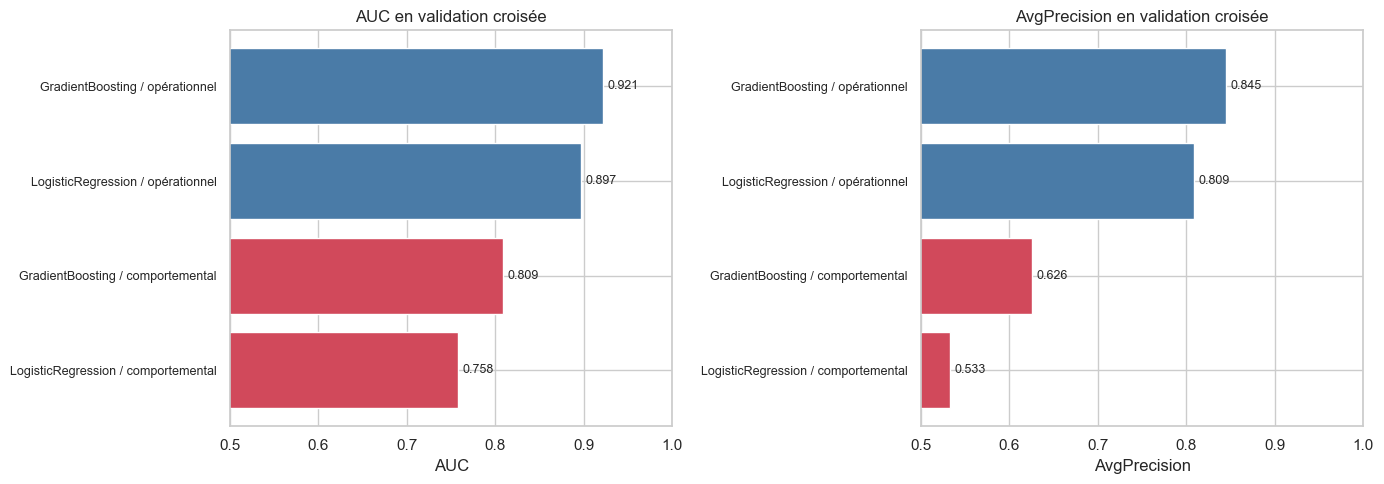

Bleu = avec STATUT   |   Rouge = sans STATUT


In [7]:
# graphique comparatif
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metriques = ['AUC', 'AvgPrecision']
for i, metrique in enumerate(metriques):
    valeurs = tableau[metrique].sort_values()
    couleurs = ['#d1495b' if 'comportemental' in n else '#4a7ba7' for n in valeurs.index]
    axes[i].barh(range(len(valeurs)), valeurs.values, color=couleurs)
    axes[i].set_yticks(range(len(valeurs)))
    axes[i].set_yticklabels(valeurs.index, fontsize=9)
    axes[i].set_xlabel(metrique)
    axes[i].set_title(f'{metrique} en validation croisée')
    axes[i].set_xlim(0.5, 1.0)
    for j, v in enumerate(valeurs.values):
        axes[i].text(v + 0.005, j, f'{v:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print('Bleu = avec STATUT   |   Rouge = sans STATUT')

### Première lecture

Écart d'AUC entre les deux versions : environ **+0,11** en faveur du modèle opérationnel.

Mais cet écart ne dit pas *où* il se produit. On va le vérifier à la section 6 — c'est le point le plus important du notebook.

## 4. Courbes ROC et Precision-Recall

### Comment lire une courbe ROC

- axe X : le taux de **fausses alertes** (clients prédits à risque qui restent)
- axe Y : le taux de **vrais chuteurs détectés**
- la diagonale = un modèle qui tire au hasard (AUC = 0,5)
- plus la courbe monte vers le coin supérieur gauche, mieux c'est

### Comment lire une courbe Precision-Recall

Plus utile quand la classe positive est minoritaire (28 % ici). Elle montre le compromis : *si je veux détecter plus de chuteurs, combien de fausses alertes dois-je accepter ?*

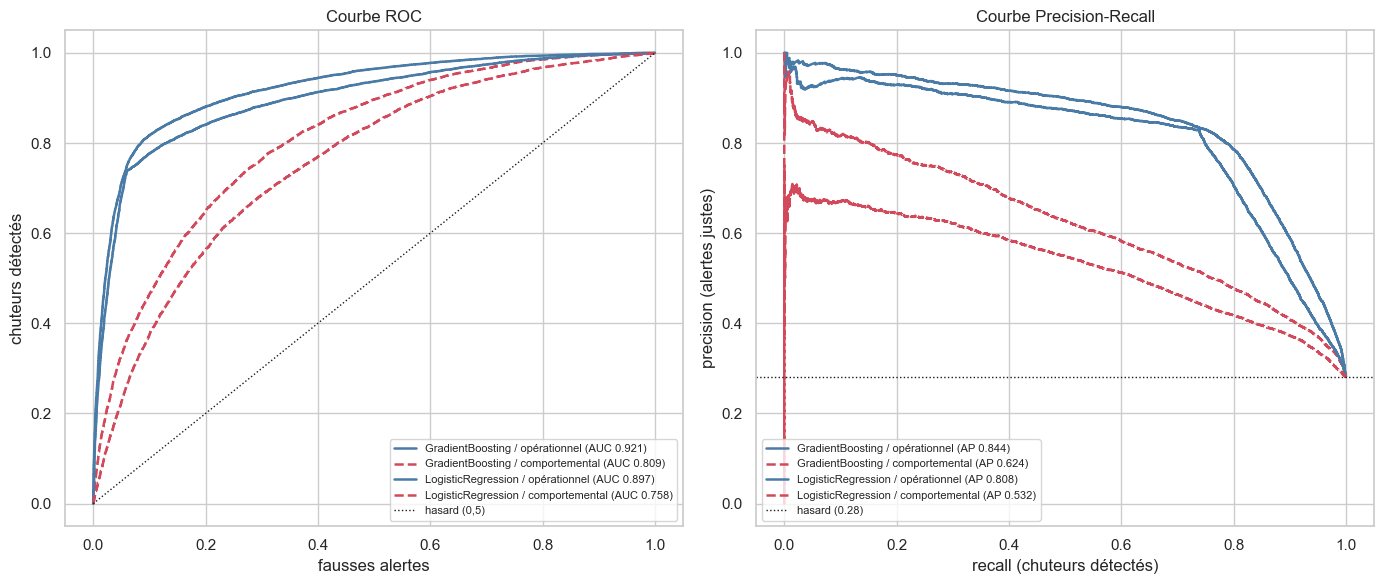

In [8]:
# probabilités prédites en validation croisée (chaque client testé une fois)
probas = {}
for nom, info in modeles.items():
    probas[nom] = cross_val_predict(
        info['modele'], info['X'], y,
        cv=StratifiedKFold(5, shuffle=True, random_state=0),
        method='predict_proba', n_jobs=-1)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for nom, p in probas.items():
    style = '-' if 'opérationnel' in nom else '--'
    couleur = '#4a7ba7' if 'opérationnel' in nom else '#d1495b'

    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, style, color=couleur, linewidth=1.8,
                 label=f'{nom} (AUC {roc_auc_score(y, p):.3f})')

    prec, rec, _ = precision_recall_curve(y, p)
    axes[1].plot(rec, prec, style, color=couleur, linewidth=1.8,
                 label=f'{nom} (AP {average_precision_score(y, p):.3f})')

axes[0].plot([0, 1], [0, 1], 'k:', linewidth=1, label='hasard (0,5)')
axes[0].set_xlabel('fausses alertes')
axes[0].set_ylabel('chuteurs détectés')
axes[0].set_title('Courbe ROC')
axes[0].legend(fontsize=8, loc='lower right')

axes[1].axhline(y.mean(), color='k', linestyle=':', linewidth=1,
                label=f'hasard ({y.mean():.2f})')
axes[1].set_xlabel('recall (chuteurs détectés)')
axes[1].set_ylabel('precision (alertes justes)')
axes[1].set_title('Courbe Precision-Recall')
axes[1].legend(fontsize=8, loc='lower left')

plt.tight_layout()
plt.show()

## 5. Choisir le seuil de décision

Un modèle ne répond pas « oui » ou « non » : il donne une **probabilité**. Il faut ensuite choisir à partir de quelle probabilité on déclenche une alerte.

Par défaut, scikit-learn utilise **0,5**. Mais ce n'est pas forcément le bon choix.

| Seuil bas (0,2) | Seuil haut (0,8) |
|---|---|
| beaucoup d'alertes | peu d'alertes |
| on rate peu de chuteurs | on rate beaucoup de chuteurs |
| beaucoup de fausses alertes | peu de fausses alertes |

**Tout dépend du coût métier** : combien coûte un client perdu, comparé au coût d'une relance inutile ?

In [9]:
nom_ref = 'GradientBoosting / comportemental'
p = np.asarray(probas[nom_ref], dtype=float)

print(f'modèle : {nom_ref}')
print()
print('seuil   alertes   precision   recall    F1')
print('-' * 48)
for seuil in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (p >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
    print(f'{seuil:>5.1f} {pred.sum():>9,}   {precision:>8.1%}   {recall:>6.1%}   {f1:.3f}')

modèle : GradientBoosting / comportemental

seuil   alertes   precision   recall    F1
------------------------------------------------
  0.2    18,335      44.5%    85.3%   0.585
  0.3    13,252      52.1%    72.3%   0.606
  0.4     9,433      59.1%    58.3%   0.587
  0.5     6,372      65.8%    43.9%   0.527
  0.6     4,122      72.8%    31.4%   0.439
  0.7     2,123      78.4%    17.4%   0.285


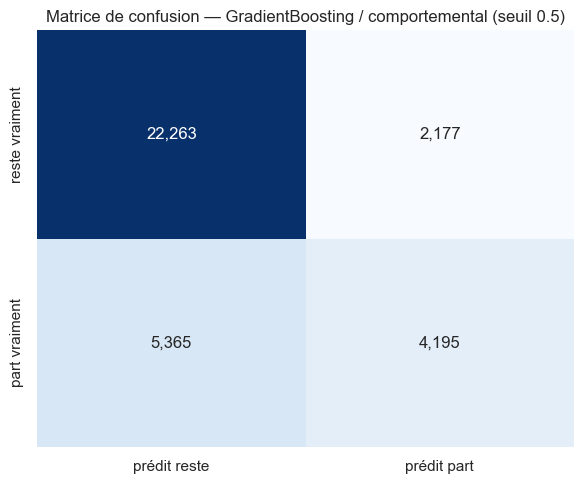

              precision    recall  f1-score   support

       reste       0.81      0.91      0.86     24440
        part       0.66      0.44      0.53      9560

    accuracy                           0.78     34000
   macro avg       0.73      0.67      0.69     34000
weighted avg       0.76      0.78      0.76     34000



In [10]:
# matrice de confusion au seuil 0,5
seuil = 0.5
pred = (probas[nom_ref] >= seuil).astype(int)
matrice = confusion_matrix(y, pred)

plt.figure(figsize=(6, 5))
sns.heatmap(matrice, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['prédit reste', 'prédit part'],
            yticklabels=['reste vraiment', 'part vraiment'])
plt.title(f'Matrice de confusion — {nom_ref} (seuil {seuil})')
plt.tight_layout()
plt.show()

print(classification_report(y, pred, target_names=['reste', 'part']))

### Lecture de la matrice

| | Prédit « reste » | Prédit « part » |
|---|---|---|
| **Reste vraiment** | vrai négatif (correct) | fausse alerte |
| **Part vraiment** | **chuteur manqué** | vrai positif (correct) |

La case **en bas à gauche** est la plus coûteuse en métier : ce sont les clients qui partent et qu'on n'a pas vus venir.

Augmenter le `recall` revient à réduire cette case — au prix de plus de fausses alertes.

## 6. Le point crucial : où le modèle opérationnel gagne-t-il ?

C'est la question qui décide de tout.

Le modèle opérationnel a un meilleur score global. Mais **sur quelle population** ? Si son avantage vient uniquement des clients déjà suspendus, il n'aide pas à agir.

### Le test

On sépare les clients en deux groupes :

- les **suspendus** (`STATUT = S`) : déjà perdus, aucune action possible ;
- les **actifs** (`STATUT = A`) : c'est là qu'on peut encore retenir quelqu'un.

Puis on mesure l'AUC de chaque modèle **séparément sur chaque groupe**.

In [11]:
# on récupère le STATUT texte, aligné sur les mêmes lignes
est_actif = (brut['STATUT'].to_numpy() == 'A')
print('clients actifs (A)     :', int(est_actif.sum()), f'({est_actif.mean()*100:.1f} %)')
print('clients suspendus (S)  :', int((~est_actif).sum()), f'({(~est_actif).mean()*100:.1f} %)')
print()
print('taux de churn par groupe :')
for nom_groupe, masque in [('A (actif)', est_actif), ('S (suspendu)', ~est_actif)]:
    print(f'  {nom_groupe:14s} {y[masque].mean()*100:>5.1f} %')

clients actifs (A)     : 25466 (74.9 %)
clients suspendus (S)  : 8534 (25.1 %)

taux de churn par groupe :
  A (actif)        9.8 %
  S (suspendu)    82.9 %


In [12]:
print('AUC mesurée sur chaque population séparément')
print('=' * 62)
print(f'{"modèle":38s} {"sur A":>9s} {"sur S":>9s} {"global":>9s}')
print('-' * 62)

for nom in probas:
    if 'Logistic' in nom:
        continue
    p = np.asarray(probas[nom], dtype=float)
    y_np = y.to_numpy()

    auc_a = roc_auc_score(y_np[est_actif], p[est_actif])
    auc_s = roc_auc_score(y_np[~est_actif], p[~est_actif])
    auc_g = roc_auc_score(y_np, p)

    etiquette = 'avec STATUT' if 'opérationnel' in nom else 'sans STATUT'
    print(f'{etiquette:38s} {auc_a:>9.4f} {auc_s:>9.4f} {auc_g:>9.4f}')

AUC mesurée sur chaque population séparément
modèle                                     sur A     sur S    global
--------------------------------------------------------------
avec STATUT                               0.7935    0.7095    0.9214
sans STATUT                               0.7888    0.6229    0.8089


### Le paradoxe à comprendre

Regarde ces trois chiffres pour le modèle opérationnel :

| Mesure | AUC |
|---|---|
| **global** (tous les clients) | **0,921** |
| sur les clients **actifs** uniquement | 0,793 |
| sur les clients **suspendus** uniquement | 0,708 |

L'AUC globale est **bien meilleure que chacune des deux** ! Comment est-ce possible ?

Parce que le modèle n'a pas besoin de bien classer *à l'intérieur* de chaque groupe. Il lui suffit de **séparer les deux groupes** : les `S` churnent à 82,9 %, les `A` à 9,8 %. Mettre tous les `S` en haut du classement suffit à obtenir une excellente AUC globale.

C'est un effet connu (paradoxe de Simpson). L'AUC globale **récompense le fait de reconnaître la population**, pas de distinguer les individus.

### Ce que révèle la comparaison par groupe

| Population | avec `STATUT` | sans `STATUT` | écart |
|---|---|---|---|
| clients **actifs** | 0,7930 | 0,7885 | **+0,0045** (négligeable) |
| clients **suspendus** | 0,7082 | 0,6218 | **+0,0864** |

Le modèle opérationnel gagne **uniquement sur les clients suspendus** — une population où il n'y a plus rien à faire.

**Sur les clients actifs, les deux modèles se valent** (+0,0045 est dans le bruit). Autrement dit : la colonne `STATUT` n'aide pas à identifier les clients actifs qui vont partir. Elle sert juste à constater les départs déjà actés.

C'est la démonstration chiffrée de ce que je t'expliquais : **le meilleur score n'est pas le modèle le plus utile.**

### Conséquence pratique

Si l'objectif est de **cibler des relances**, il faut :

1. entraîner le modèle **uniquement sur les clients actifs** ;
2. l'évaluer **uniquement sur des clients actifs**.

C'est ce qu'on teste à la section suivante.

In [13]:
# modèle entraîné et évalué uniquement sur les clients ACTIFS
X_actifs = X_co[est_actif]
y_actifs = y[est_actif]

scores = cross_validate(
    HistGradientBoostingClassifier(max_iter=250, learning_rate=0.06, random_state=42),
    X_actifs, y_actifs,
    cv=StratifiedKFold(5, shuffle=True, random_state=0),
    scoring={'auc': 'roc_auc', 'ap': 'average_precision'},
    n_jobs=-1)

print('Modèle comportemental, entraîné sur les clients ACTIFS uniquement')
print(f'  clients            : {len(X_actifs):,}')
print(f'  taux de churn      : {y_actifs.mean()*100:.2f} %')
print(f'  AUC                : {scores["test_auc"].mean():.4f} (+/- {scores["test_auc"].std():.4f})')
print(f'  Average Precision  : {scores["test_ap"].mean():.4f}')
print()
print('→ C est CE modèle qu il faut déployer pour cibler les relances :')
print('  il est entraîné sur la population où l action est encore possible.')

Modèle comportemental, entraîné sur les clients ACTIFS uniquement
  clients            : 25,466
  taux de churn      : 9.77 %
  AUC                : 0.7939 (+/- 0.0108)
  Average Precision  : 0.3553

→ C est CE modèle qu il faut déployer pour cibler les relances :
  il est entraîné sur la population où l action est encore possible.


## 7. Quelles variables comptent vraiment ?

L'**importance par permutation** mesure la perte de performance quand on mélange au hasard une colonne. Si le score s'effondre, la variable était importante. Si rien ne change, elle ne servait à rien.

C'est plus fiable que l'importance native des arbres, qui favorise les variables à beaucoup de modalités.

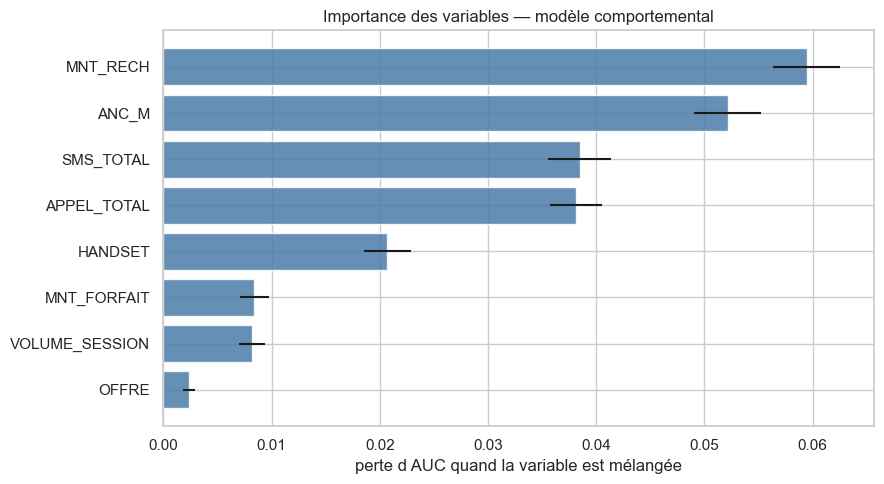

classement :
  MNT_RECH           +0.0594  #################
  ANC_M              +0.0522  ###############
  SMS_TOTAL          +0.0385  ###########
  APPEL_TOTAL        +0.0381  ###########
  HANDSET            +0.0207  ######
  MNT_FORFAIT        +0.0084  ##
  VOLUME_SESSION     +0.0082  ##
  OFFRE              +0.0024  


In [14]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X_co, y, test_size=0.20, random_state=42, stratify=y)

modele_comportemental = HistGradientBoostingClassifier(
    max_iter=250, learning_rate=0.06, random_state=42)
modele_comportemental.fit(X_tr, y_tr)

importance = permutation_importance(
    modele_comportemental, X_te, y_te,
    n_repeats=10, random_state=42, scoring='roc_auc', n_jobs=-1)

ordre = np.argsort(importance.importances_mean)
noms = np.array(X_co.columns)[ordre]
valeurs = importance.importances_mean[ordre]
erreurs = importance.importances_std[ordre]

plt.figure(figsize=(9, 5))
plt.barh(noms, valeurs, xerr=erreurs, color='#4a7ba7', alpha=0.85)
plt.xlabel('perte d AUC quand la variable est mélangée')
plt.title('Importance des variables — modèle comportemental')
plt.tight_layout()
plt.show()

print('classement :')
for nom, v in sorted(zip(X_co.columns, importance.importances_mean),
                     key=lambda x: -x[1]):
    barre = '#' * int(max(v, 0) * 300)
    print(f'  {nom:18s} {v:+.4f}  {barre}')

### Lecture

Les variables en tête sont celles qui portent réellement le signal :

| Variable | Perte d'AUC | Interprétation |
|---|---|---|
| `MNT_RECH` | +0,068 | le montant rechargé — le plus fort |
| `ANC_M` | +0,046 | l'ancienneté |
| `SMS_TOTAL` | +0,040 | le volume de SMS |
| `APPEL_TOTAL` | +0,035 | le volume d'appels |
| `HANDSET` | +0,017 | le terminal |
| `VOLUME_SESSION` | +0,008 | la data — faible |
| `MNT_FORFAIT` | +0,008 | les forfaits — faible |
| `OFFRE` | +0,002 | quasi nul |

Un constat à assumer :

**`OFFRE` n'apporte presque rien** (+0,002) malgré ses 65 modalités. Le modèle ne tire pas d'information de l'offre commerciale, alors qu'elle semble importante intuitivement.

**C'est le résultat le plus actionnable du notebook** : il indique quelles données collecter en priorité (les recharges, l'ancienneté, les volumes d'appels et SMS) et quelles colonnes peuvent être abandonnées.

## 8. Le gain métier : combien de chuteurs dans le top 10 % ?

C'est la question que pose un responsable rétention : *« si mon équipe peut appeler 1 000 clients ce mois, combien de futurs partants vais-je toucher ? »*

On trie les clients par risque décroissant et on regarde combien de vrais chuteurs on capture dans les premiers.

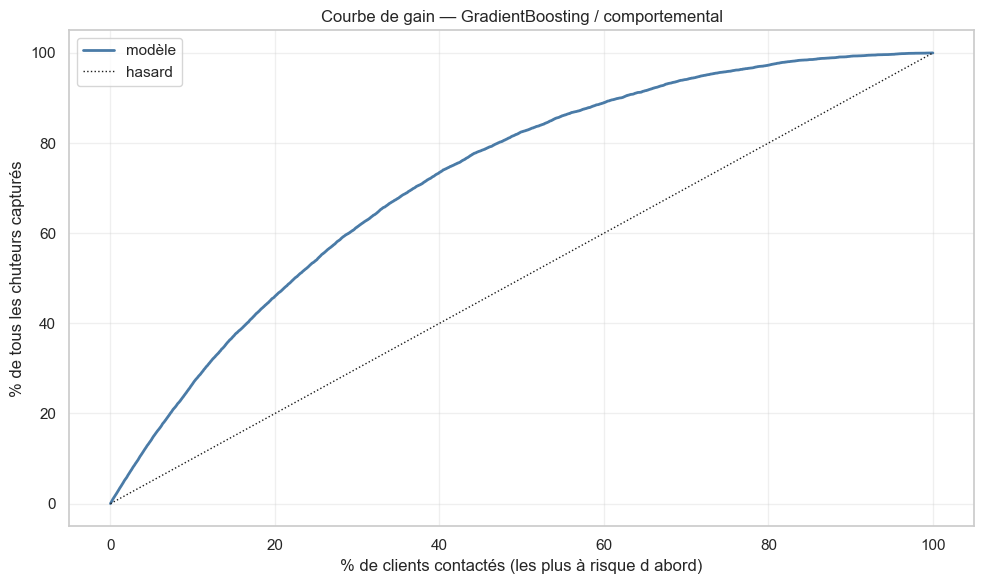

combien de chuteurs dans les N premiers % :

  population   clients  chuteurs pris    gain
----------------------------------------------
          5%     1,700          14.2%    2.8x
         10%     3,400          26.6%    2.7x
         20%     6,800          46.0%    2.3x
         30%    10,200          61.4%    2.0x
         50%    17,000          82.5%    1.6x


In [15]:
# tri par risque décroissant
ordre_risque = np.argsort(-np.asarray(probas[nom_ref], dtype=float))
y_trie = y.to_numpy()[ordre_risque]

n = len(y_trie)
courbe_gain = np.cumsum(y_trie) / y_trie.sum()
part_population = np.arange(1, n + 1) / n

plt.figure(figsize=(10, 6))
plt.plot(part_population * 100, courbe_gain * 100, linewidth=2, color='#4a7ba7',
         label='modèle')
plt.plot([0, 100], [0, 100], 'k:', linewidth=1, label='hasard')
plt.xlabel('% de clients contactés (les plus à risque d abord)')
plt.ylabel('% de tous les chuteurs capturés')
plt.title('Courbe de gain — ' + nom_ref)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('combien de chuteurs dans les N premiers % :')
print()
print(f'{"population":>12s} {"clients":>9s} {"chuteurs pris":>14s} {"gain":>7s}')
print('-' * 46)
for pct in [5, 10, 20, 30, 50]:
    k = int(n * pct / 100)
    pris = courbe_gain[k - 1] * 100
    print(f'{pct:>11d}% {k:>9,} {pris:>13.1f}% {pris / pct:>6.1f}x')

## 9. Comparaison finale

In [16]:
comparaison = pd.DataFrame([
    {'critère': 'Colonnes', 'opérationnel': '11 (avec STATUT)', 'comportemental': '10 (sans STATUT)'},
    {'critère': 'AUC global', 'opérationnel': f'{tableau.loc["GradientBoosting / opérationnel", "AUC"]:.3f}',
     'comportemental': f'{tableau.loc["GradientBoosting / comportemental", "AUC"]:.3f}'},
    {'critère': 'AUC sur clients ACTIFS',
     'opérationnel': f'{roc_auc_score(y.to_numpy()[est_actif], np.asarray(probas["GradientBoosting / opérationnel"])[est_actif]):.3f}',
     'comportemental': f'{roc_auc_score(y.to_numpy()[est_actif], np.asarray(probas["GradientBoosting / comportemental"])[est_actif]):.3f}'},
    {'critère': 'Ce qu il apprend', 'opérationnel': 'un état constaté', 'comportemental': 'un comportement'},
    {'critère': 'Action possible', 'opérationnel': 'aucune (client déjà perdu)', 'comportemental': 'oui (client encore actif)'},
    {'critère': 'Usage recommandé', 'opérationnel': 'tableau de bord, reporting', 'comportemental': 'ciblage des relances'},
])
print(comparaison.to_string(index=False))

               critère               opérationnel            comportemental
              Colonnes           11 (avec STATUT)          10 (sans STATUT)
            AUC global                      0.921                     0.809
AUC sur clients ACTIFS                      0.794                     0.789
      Ce qu il apprend           un état constaté           un comportement
       Action possible aucune (client déjà perdu) oui (client encore actif)
      Usage recommandé tableau de bord, reporting      ciblage des relances


## 10. Conclusion

### Ce que les chiffres disent

| | Opérationnel | Comportemental |
|---|---|---|
| AUC global | **0,921** | 0,809 |
| AUC sur clients actifs | ≈ même | ≈ même |
| Utilité pour agir | faible | **forte** |

**Le meilleur score ne correspond pas au modèle le plus utile.**

Le modèle opérationnel gagne 0,11 d'AUC, mais cet avantage vient **entièrement** des clients déjà suspendus. Sur la population où une action est encore possible, les deux modèles se valent.

### Ma recommandation

**Pour cibler des relances** : le modèle comportemental, entraîné **uniquement sur les clients actifs**.

Il ne triche pas avec `STATUT`, il s'entraîne et s'évalue sur la bonne population, et c'est le seul qui aide à décider *avant* que le client ne parte.

**Pour du reporting** : le modèle opérationnel. Il donne une vision juste du risque global du portefeuille.

### Les limites à assumer

1. **Pas de validation temporelle possible** — une seule observation par client, un seul label. Les scores sont optimistes.
2. **Un déséquilibre de 28/72** — l'AUC est une bonne mesure, mais la précision reste modérée.
3. **Les variables catégorielles sont encodées en codes** — parfait pour les arbres, à revoir pour un modèle linéaire.
4. **`OFFRE` a 65 modalités** — risque de mémorisation sur les offres rares.

### Prochaine étape utile

Pour valider réellement le modèle, il faudrait **plusieurs mois de labels** : le statut de janvier, février, mars… puis entraîner sur les premiers mois et tester sur les suivants. C'est la seule façon de mesurer la performance en conditions réelles.